# Credit card default: building a bank-style credit scorecard and expected credit loss

**The question.** A bank has 30,000 credit card customers. Which of them will miss next month's payment, how confident can we be, and how much money should the bank expect to lose?

**What this notebook does**, the way a bank's credit risk team would:

1. Turn six months of payment history into a few clear **risk characteristics**.
2. Measure each one's predictive power with **Weight of Evidence (WoE)** and **Information Value (IV)**.
3. Fit a **logistic regression** and convert it into a **points-based scorecard**.
4. **Validate** it on clients the model never saw (Gini, KS, calibration).
5. Use it: **approval cut-offs** and **expected credit loss** (PD × LGD × EAD).

**Data:** 30,000 credit card clients in Taiwan, April–September 2005. Yeh, I. (2009), *Default of Credit Card Clients*, UCI Machine Learning Repository, [doi:10.24432/C55S3H](https://doi.org/10.24432/C55S3H) (CC BY 4.0). Amounts are in New Taiwan dollars (NT$).

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.isdir("creditrisk"):                   # Google Colab: fetch the code from GitHub
    os.system("git clone -q https://github.com/DylanAmbrose892/credit-risk-scorecard.git")
    os.chdir("credit-risk-scorecard")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from creditrisk import core as cr

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
NAVY, GREY, RED = "#1f3864", "#9aa7b8", "#c0392b"
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. The data

In [2]:
df = cr.load_data("data/default_of_credit_card_clients.xls")
y = df[cr.TARGET]
print(f"{len(df):,} clients, {df.shape[1] - 1} variables, no missing values: {df.isna().sum().sum() == 0}")
print(f"Defaulted the next month: {y.sum():,} clients ({y.mean():.1%})")
df.head()

30,000 clients, 23 variables, no missing values: True
Defaulted the next month: 6,636 clients (22.1%)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
ID,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Each client has:

* **Credit limit** (`LIMIT_BAL`) and **demographics** (sex, education, marital status, age)
* **Repayment status** for each of the last six months (`PAY_1` = September … `PAY_6` = April): −2 no balance, −1 paid in full, 0 paid the minimum, 1 = one month late, 2 = two months late, and so on
* **Bill amount** and **amount paid** for each month
* **Target:** did the client default in October 2005?

## 2. What does the raw data say?

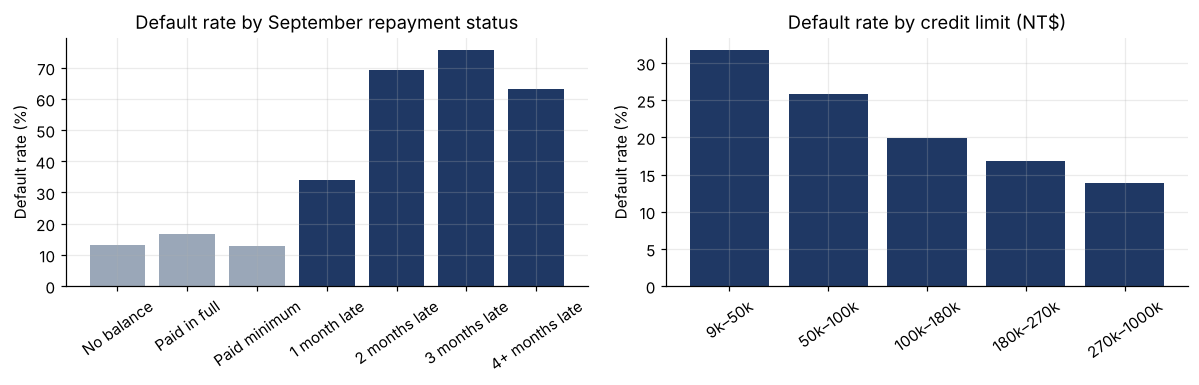

In [3]:
status_rate = y.groupby(df["PAY_1"].clip(-2, 4)).agg(["mean", "size"])
labels = {-2: "No balance", -1: "Paid in full", 0: "Paid minimum", 1: "1 month late", 2: "2 months late", 3: "3 months late", 4: "4+ months late"}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.bar([labels[i] for i in status_rate.index], status_rate["mean"] * 100,
       color=[GREY if i < 1 else NAVY for i in status_rate.index])
ax.set_ylabel("Default rate (%)"); ax.set_title("Default rate by September repayment status")
ax.tick_params(axis="x", rotation=35)

limit_band = pd.qcut(df["LIMIT_BAL"], 5)
lim = y.groupby(limit_band, observed=True).mean() * 100
ax = axes[1]
ax.bar([f"{int(i.left/1000)}k–{int(i.right/1000)}k" for i in lim.index], lim.values, color=NAVY)
ax.set_ylabel("Default rate (%)"); ax.set_title("Default rate by credit limit (NT$)")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout(); fig.savefig("figures/01_default_drivers.png", dpi=150)
plt.show()

Two things jump out:

* **Recent lateness is by far the strongest signal.** Clients 2+ months behind in September default about 70% of the time, compared with roughly 13–17% for clients who are up to date.
* **Higher limits mean lower risk.** Banks give larger limits to clients they already trust, so the limit carries the bank's own past judgement.

## 3. A deliberate choice: no demographics

The data includes sex, marital status, education and age. **This scorecard does not use them.** Many regulators restrict lending decisions based on characteristics like these, and a model that charges someone more for being single or female is hard to defend. Section 8 measures how much accuracy this costs. The answer: very little.

## 4. Building the characteristics

A scorecard works best with a handful of clear, explainable characteristics. These five come only from the client's own behaviour:

| Characteristic | Meaning |
|---|---|
| `latest_status` | Repayment status in the most recent month |
| `months_late_6m` | How many of the last 6 months the client was late |
| `credit_limit` | Credit limit granted by the bank |
| `repayment_ratio` | Share of last month's bill that was actually repaid |
| `avg_util_6m` | Average balance ÷ limit over 6 months (how "maxed out" the card is) |

Before fitting anything, we split clients into **70% training** and **30% test**. Everything is learned on the training set and judged on the test set, so the results show how the scorecard would do on new clients.

In [4]:
chars = cr.build_characteristics(df)
train_idx, test_idx = train_test_split(df.index, test_size=0.30, stratify=y, random_state=42)
Xtr, Xte, ytr, yte = chars.loc[train_idx], chars.loc[test_idx], y.loc[train_idx], y.loc[test_idx]
print(f"Training: {len(Xtr):,} clients  |  Test: {len(Xte):,} clients  |  default rate {ytr.mean():.1%} / {yte.mean():.1%}")

Training: 21,000 clients  |  Test: 9,000 clients  |  default rate 22.1% / 22.1%


## 5. Weight of Evidence and Information Value

Each characteristic is split into **bins** (groups). For every bin we compute its **Weight of Evidence**:

```
WoE = ln( share of all good clients in the bin / share of all bad clients in the bin )
```

Positive WoE means the bin is **safer** than average; negative means **riskier**. Adding the bins up gives each characteristic's **Information Value (IV)**, the standard banking measure of how useful it is.

In [5]:
enc = cr.WoEEncoder().fit(Xtr, ytr)
iv = enc.iv_.to_frame("IV")
iv["strength"] = iv["IV"].map(cr.iv_strength)
iv

,IV,strength
latest_status,0.893,Very strong (check for leakage)
months_late_6m,0.869,Very strong (check for leakage)
credit_limit,0.167,Medium
avg_util_6m,0.113,Medium
repayment_ratio,0.093,Weak


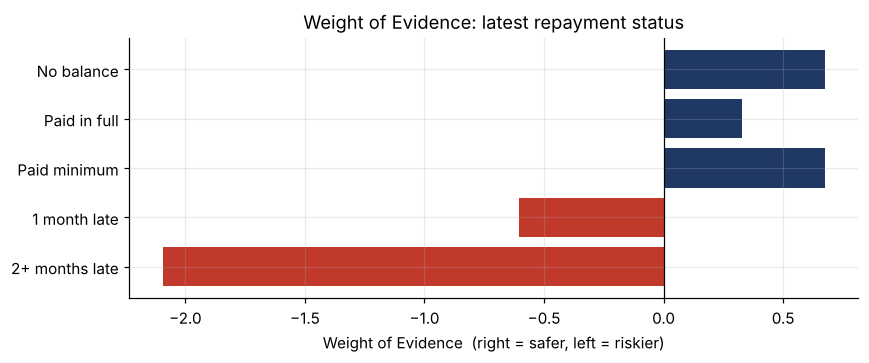

In [6]:
t = enc.tables_["latest_status"]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh([b[3:] for b in t.index][::-1], t["woe"][::-1], color=[NAVY if w > 0 else RED for w in t["woe"][::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Weight of Evidence  (right = safer, left = riskier)")
ax.set_title("Weight of Evidence: latest repayment status")
fig.tight_layout(); fig.savefig("figures/02_woe_latest_status.png", dpi=150)
plt.show()

Repayment behaviour (`latest_status`, `months_late_6m`) is **very strong**. The rule of thumb flags IV above 0.5 for a leakage check: is the variable secretly using the answer? Here it isn't. The repayment status is recorded *before* the default month, so it is a fair predictor, just a powerful one. The balance and limit characteristics are **medium** or **weak** individually but add independent information.

## 6. The model, and turning it into a scorecard

We fit a logistic regression on the WoE values. Then we rescale it into **points** using the standard convention:

* **600 points** = odds of 50 good clients to 1 bad
* every **20 more points doubles** the odds of being good

A client's score is simply the sum of the points for their bins. Higher score = safer.

In [7]:
model = cr.fit_logistic(enc.transform(Xtr), ytr)
print("Coefficients (all negative = every characteristic pushes risk in the expected direction):")
print(pd.Series(model.coef_[0], index=enc.tables_.keys()).round(3).to_string())

card = cr.scorecard(enc, model)
card.style.format({"default_rate": "{:.1%}", "woe": "{:.2f}"}).hide(axis="index")

Coefficients (all negative = every characteristic pushes risk in the expected direction):
latest_status     -0.601
months_late_6m    -0.483
credit_limit      -0.435
repayment_ratio   -0.111
avg_util_6m       -0.353


characteristic,bin,clients,default_rate,woe,points
latest_status,a. No balance,1933,12.6%,0.67,116
latest_status,b. Paid in full,3971,17.0%,0.33,110
latest_status,c. Paid minimum,10285,12.6%,0.67,116
latest_status,d. 1 month late,2616,34.2%,-0.60,94
latest_status,e. 2+ months late,2195,69.8%,-2.10,68
months_late_6m,0,13910,11.5%,0.79,116
months_late_6m,1,3109,29.9%,-0.41,99
months_late_6m,2,1339,39.7%,-0.84,93
months_late_6m,3-6,2642,60.2%,-1.67,81
credit_limit,"1. min to 50,000",5377,32.1%,-0.51,98


### Scoring one client, step by step

In [8]:
example = Xte.index[7]
b = enc.bins(Xte.loc[[example]]).T.iloc[:, 0]
walk = pd.DataFrame({"bin": b})
walk["points"] = [card.set_index(["characteristic", "bin"]).loc[(c, v), "points"] for c, v in b.items()]
total = walk["points"].sum()
display(walk)
print(f"Total score: {total:.0f}  ->  probability of default {cr.score_to_pd(total):.1%}   "
      f"(actually defaulted: {'yes' if yte[example] else 'no'})")

,bin,points
latest_status,c. Paid minimum,116
months_late_6m,0,116
credit_limit,"1. min to 50,000",98
repayment_ratio,3. 0.05 to 0.09,105
avg_util_6m,4. 0.45 to 0.76,103


Total score: 538  ->  probability of default 14.6%   (actually defaulted: yes)


A score is a probability, not a verdict. This client had a **15% chance** of default, roughly 1 in 7, and turned out to be one of the unlucky ones. A scorecard is judged on how well it ranks and prices *groups* of clients, which is what the next section tests.

## 7. Validation on the test set

Three standard checks:

* **Gini** (= 2 × AUC − 1): how well the score *ranks* bad clients below good ones. 0 = random, 1 = perfect. Retail scorecards are commonly around 0.4–0.6.
* **KS**: the biggest gap between the score distributions of good and bad clients.
* **Calibration**: does a predicted 30% default rate really mean about 30% default?

In [9]:
score_tr = cr.score(enc, card, Xtr)
score_te = cr.score(enc, card, Xte)
pd_te = cr.score_to_pd(score_te)

metrics = pd.DataFrame({
    "Training": [cr.gini(ytr, -score_tr), cr.ks(ytr, -score_tr)],
    "Test": [cr.gini(yte, -score_te), cr.ks(yte, -score_te)],
}, index=["Gini", "KS"])
metrics

,Training,Test
Gini,0.531,0.501
KS,0.417,0.392


Training and test results are close (Gini 0.53 vs 0.50), so the scorecard is **not overfitting** much: it should hold up on new clients.

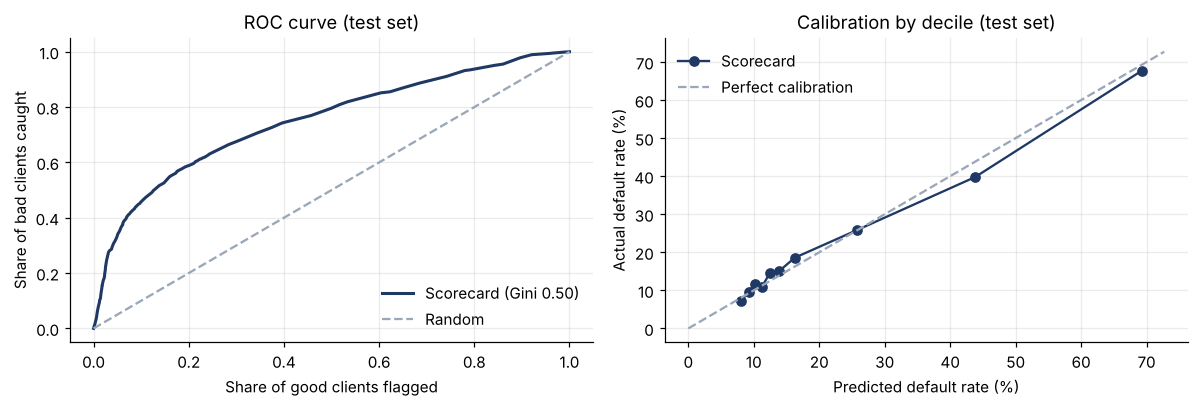

,predicted,actual,clients
group,,,
1,8.0%,7.2%,900
2,9.2%,9.6%,900
3,10.2%,11.8%,900
4,11.3%,11.0%,900
5,12.5%,14.7%,900
6,13.9%,15.1%,900
7,16.2%,18.6%,900
8,25.8%,25.9%,900
9,43.8%,39.8%,900


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
fpr, tpr, _ = roc_curve(yte, -score_te)
ax = axes[0]
ax.plot(fpr, tpr, color=NAVY, lw=2, label=f"Scorecard (Gini {cr.gini(yte, -score_te):.2f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random")
ax.set_xlabel("Share of good clients flagged"); ax.set_ylabel("Share of bad clients caught")
ax.set_title("ROC curve (test set)"); ax.legend(frameon=False, loc="lower right")

cal = cr.calibration_table(yte, pd_te)
ax = axes[1]
ax.plot(cal["predicted"] * 100, cal["actual"] * 100, marker="o", color=NAVY, label="Scorecard")
lim_ = max(cal["predicted"].max(), cal["actual"].max()) * 100 * 1.05
ax.plot([0, lim_], [0, lim_], color=GREY, ls="--", label="Perfect calibration")
ax.set_xlabel("Predicted default rate (%)"); ax.set_ylabel("Actual default rate (%)")
ax.set_title("Calibration by decile (test set)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/03_validation.png", dpi=150)
plt.show()
cal.style.format({"predicted": "{:.1%}", "actual": "{:.1%}"})

## 8. Benchmark: how much do we give up for a simple, fair model?

We compare the scorecard with a **gradient boosting** model, a much more flexible machine-learning method, trained on all the raw columns. Once without demographics, and once with them.

In [11]:
behaviour = [c for c in df.columns if c not in cr.DEMOGRAPHICS + [cr.TARGET]]
rows = {"Scorecard (5 characteristics, points)": cr.gini(yte, -score_te)}
for name, cols in [("Gradient boosting, behaviour only (19 columns)", behaviour),
                   ("Gradient boosting, + demographics (23 columns)", behaviour + cr.DEMOGRAPHICS)]:
    gb = HistGradientBoostingClassifier(random_state=0).fit(df.loc[train_idx, cols], ytr)
    rows[name] = cr.gini(yte, gb.predict_proba(df.loc[test_idx, cols])[:, 1])
bench = pd.Series(rows, name="Test Gini").to_frame()
bench

,Test Gini
"Scorecard (5 characteristics, points)",0.501
"Gradient boosting, behaviour only (19 columns)",0.548
"Gradient boosting, + demographics (23 columns)",0.555


* The black-box model ranks clients somewhat better (Gini about 0.55 vs 0.50), using 19 columns instead of 5 characteristics.
* **Adding demographics barely helps at all.** Leaving them out is close to free in accuracy, and much easier to defend.
* The scorecard wins on everything else banks care about: every point can be explained to a customer, an auditor or a regulator.

## 9. Using the score: approval cut-offs

Group test clients into 10 equal-sized score bands and look at the default rate in each:

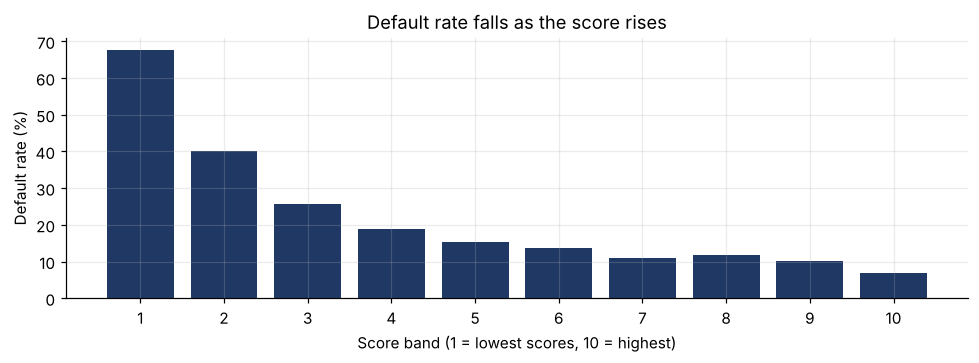

,min_score,max_score,default_rate
band,,,
1,450,478,67.6%
2,478,509,40.1%
3,509,527,25.7%
4,527,538,19.0%
5,538,542,15.4%
6,542,546,13.7%
7,546,549,11.0%
8,549,551,11.8%
9,551,555,10.2%


In [12]:
bands = pd.qcut(score_te.rank(method="first"), 10, labels=range(1, 11))
band_tbl = pd.DataFrame({"score": score_te, "default": yte, "band": bands}).groupby("band", observed=True).agg(
    min_score=("score", "min"), max_score=("score", "max"), default_rate=("default", "mean"))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(band_tbl.index.astype(str), band_tbl["default_rate"] * 100, color=NAVY)
ax.set_xlabel("Score band (1 = lowest scores, 10 = highest)"); ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate falls as the score rises")
fig.tight_layout(); fig.savefig("figures/04_score_bands.png", dpi=150)
plt.show()
band_tbl.style.format({"default_rate": "{:.1%}", "min_score": "{:.0f}", "max_score": "{:.0f}"})

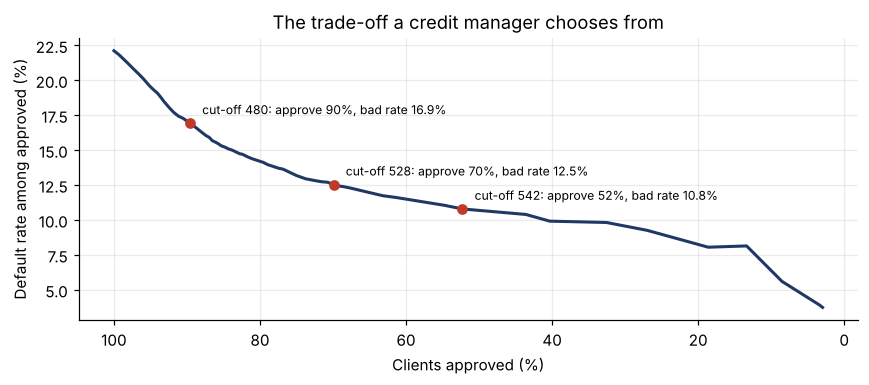

In [13]:
cuts = np.arange(score_te.min(), score_te.max(), 2)
strategy = pd.DataFrame({
    "cut_off": cuts,
    "approval_rate": [(score_te >= c).mean() for c in cuts],
    "bad_rate_approved": [yte[score_te >= c].mean() for c in cuts],
})

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(strategy["approval_rate"] * 100, strategy["bad_rate_approved"] * 100, color=NAVY, lw=2)
for target in [0.9, 0.7, 0.5]:
    r = strategy.iloc[(strategy["approval_rate"] - target).abs().argmin()]
    ax.scatter(r["approval_rate"] * 100, r["bad_rate_approved"] * 100, color=RED, zorder=3)
    ax.annotate(f"cut-off {r['cut_off']:.0f}: approve {r['approval_rate']:.0%}, bad rate {r['bad_rate_approved']:.1%}",
                (r["approval_rate"] * 100, r["bad_rate_approved"] * 100), xytext=(8, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel("Clients approved (%)"); ax.set_ylabel("Default rate among approved (%)")
ax.set_title("The trade-off a credit manager chooses from")
ax.invert_xaxis()
fig.tight_layout(); fig.savefig("figures/05_strategy_curve.png", dpi=150)
plt.show()

Reading the curve from left to right: approving fewer clients gives a lower default rate, but means less business. The credit manager picks the point that balances growth against losses. The scorecard makes that choice explicit.

## 10. Expected credit loss

Banks set aside money for expected losses (under IFRS 9 in Malaysia and Taiwan alike). The basic formula is:

```
Expected Loss = PD × LGD × EAD
```

* **PD**: probability of default, from the scorecard
* **EAD** (exposure at default): current balance + 50% of the unused limit, because customers often draw more before defaulting (*assumed credit conversion factor*)
* **LGD** (loss given default): 75% of the exposure is lost (*assumed*, typical for unsecured card debt)

The dataset has no recovery data, so LGD and CCF are stated assumptions. The sensitivity table shows how much they matter.

Test portfolio exposure: NT$989M
Expected credit loss:    NT$134M  (13.6% of exposure)
Lowest score band holds 24% of expected loss with 7% of exposure


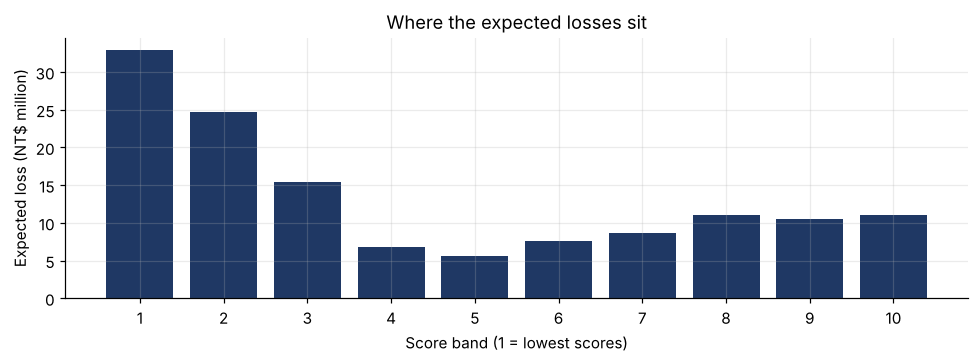

In [14]:
ead = cr.exposure_at_default(df.loc[test_idx])
el = cr.expected_loss(pd_te, ead)

port = pd.DataFrame({"band": bands, "ead": ead, "el": el}).groupby("band", observed=True).sum()
port["el_rate"] = port["el"] / port["ead"]
print(f"Test portfolio exposure: NT${ead.sum() / 1e6:,.0f}M")
print(f"Expected credit loss:    NT${el.sum() / 1e6:,.0f}M  ({el.sum() / ead.sum():.1%} of exposure)")
print(f"Lowest score band holds {port['el'].iloc[0] / port['el'].sum():.0%} of expected loss "
      f"with {port['ead'].iloc[0] / port['ead'].sum():.0%} of exposure")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(port.index.astype(str), port["el"] / 1e6, color=NAVY)
ax.set_xlabel("Score band (1 = lowest scores)"); ax.set_ylabel("Expected loss (NT$ million)")
ax.set_title("Where the expected losses sit")
fig.tight_layout(); fig.savefig("figures/06_expected_loss.png", dpi=150)
plt.show()

In [15]:
sens = pd.DataFrame(
    [[cr.expected_loss(pd_te, cr.exposure_at_default(df.loc[test_idx], ccf), lgd).sum() / 1e6 for ccf in (0.25, 0.5, 0.75)]
     for lgd in (0.60, 0.75, 0.90)],
    index=["LGD 60%", "LGD 75%", "LGD 90%"], columns=["CCF 25%", "CCF 50%", "CCF 75%"])
print("Expected credit loss (NT$ million) under different assumptions:")
sens.round(0).astype(int)

Expected credit loss (NT$ million) under different assumptions:


,CCF 25%,CCF 50%,CCF 75%
LGD 60%,83,107,131
LGD 75%,104,134,164
LGD 90%,125,161,197


## 11. Limitations

* **Old, unusual data.** Taiwan in 2005 was in the middle of a credit card debt crisis, so default rates (22%) are far above a normal portfolio. The method transfers; the numbers don't.
* **A behavioural scorecard, not an application one.** It scores existing customers using their payment history. A scorecard for new applicants would need different data.
* **One-month horizon.** IFRS 9 needs 12-month and lifetime PDs; this target is next month only.
* **LGD and CCF are assumptions.** With recovery data they would be estimated, ideally by segment.
* **Point-in-time.** A real scorecard is monitored for drift (Population Stability Index) and recalibrated as the economy changes.

## 12. Conclusion

Five behavioural characteristics, converted into an explainable points scorecard, rank defaulters well (test Gini about 0.50), are well calibrated, and lose little accuracy against a black-box model, without using any demographic information. Combined with LGD and EAD assumptions, the same score drives approval decisions and expected credit loss provisions.